# Model visualizations
Compare **all six rating models and all four success models** in one place. Graphs read checked reports saved by the model notebooks; opening this notebook does not retrain models or change CSVs.

First save and Run All in each model notebook, then run this notebook from `Data_visualization/` with `ds6001`. If a model's code or dataset changed, rerun that model before refreshing these graphs. Missing or stale reports stop with instructions instead of silently showing old results.

## Plot controls
Choose **`Selected`** for the final validation-selected model or **`Original`** for the original fixed model. All graphs use later-test movies unless labeled training/validation. Optional PNG export writes only into this folder's ignored `figures/` directory.

In [1]:
MODEL_VARIANT = "Selected"  # Change to "Original" to inspect the fixed baseline model.
SAVE_FIGURES = False        # True saves every figure as a PNG in figures/.
RATING_MODELS = ["simple_model", "linear_model", "ridge_model", "support_vector", "random_forest", "gradient_boosting"]
SUCCESS_MODELS = ["simple_model", "logistic_regression", "random_forest", "gradient_boosting"]
assert MODEL_VARIANT in ["Original", "Selected"]
assert RATING_MODELS and SUCCESS_MODELS

In [2]:
from pathlib import Path
import importlib.util
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

spec = importlib.util.spec_from_file_location("project_model_reports", Path("model_reports.py"))
report_tools = importlib.util.module_from_spec(spec)
spec.loader.exec_module(report_tools)
rating_reports = report_tools.load_reports("rating", RATING_MODELS, MODEL_VARIANT)
success_reports = report_tools.load_reports("success", SUCCESS_MODELS, MODEL_VARIANT)
LABELS = {
    "simple_model": "Simple", "linear_model": "Linear", "ridge_model": "Ridge",
    "support_vector": "SVR", "random_forest": "Random Forest",
    "gradient_boosting": "Gradient Boosting", "logistic_regression": "Logistic",
}
BLUE, GRAY = "#2a78d6", "#a7afb9"

def finish(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        Path("figures").mkdir(exist_ok=True)
        fig.savefig(Path("figures") / f"{MODEL_VARIANT.lower()}_{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

def panel_grid(count, width=12, height=3.5):
    rows = math.ceil(count / 2)
    fig, axes = plt.subplots(rows, 2, figsize=(width, rows * height), squeeze=False)
    for ax in axes.flat[count:]:
        ax.set_visible(False)
    return fig, axes.flat

def predictions(report):
    return pd.DataFrame(report["versions"][MODEL_VARIANT]["predictions"])

def metric_table(reports, split):
    return pd.DataFrame({LABELS[key]: report["versions"][MODEL_VARIANT][split + "_metrics"] for key, report in reports.items()}).T

rating_test = metric_table(rating_reports, "test")
rating_train = metric_table(rating_reports, "train")
success_test = metric_table(success_reports, "test")
success_train = metric_table(success_reports, "train")
print("Plotted model variant:", MODEL_VARIANT)
print("Reports checked against current notebook code and dataset files.")

Plotted model variant: Selected
Reports checked against current notebook code and dataset files.


## 1. What data are these graphs showing?
Ratings and success use different cohorts and targets. Compare models **within** a task; rating MAE and hit F1 are not interchangeable scores. The plots below show the same test movies for every model within a task.

,Task,Dataset,Training movies,Test movies,Date cutoff
0,Rating,data/model_data_rating.csv,9405,3871,2017-11-18
1,Success,data/model_data_success.csv,5535,1384,2017-11-18


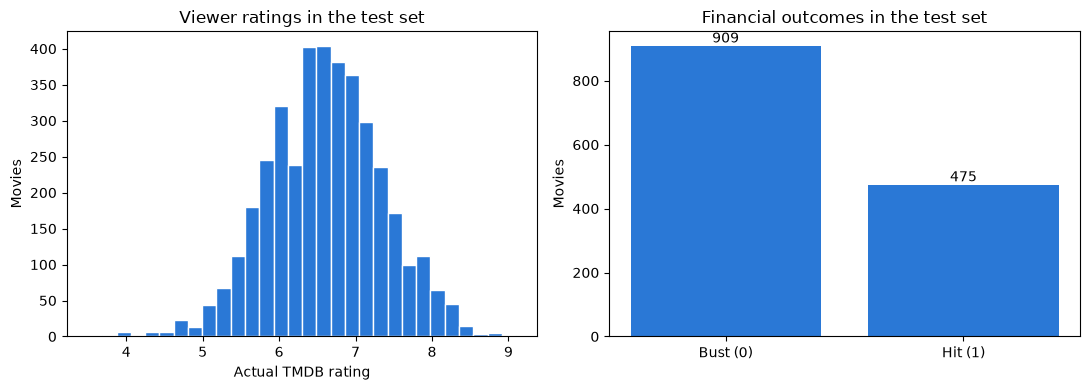

In [3]:
data_rows = []
for task, reports in [("Rating", rating_reports), ("Success", success_reports)]:
    reference = next(iter(reports.values()))
    data_rows.append([task, reference["dataset"], reference["train_count"], reference["test_count"], reference["cutoff"]])
display(pd.DataFrame(data_rows, columns=["Task", "Dataset", "Training movies", "Test movies", "Date cutoff"]))

rating_actual = predictions(next(iter(rating_reports.values())))["actual"]
success_actual = predictions(next(iter(success_reports.values())))["actual"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(rating_actual, bins=30, color=BLUE, edgecolor="white")
axes[0].set(title="Viewer ratings in the test set", xlabel="Actual TMDB rating", ylabel="Movies")
counts = success_actual.value_counts().reindex([0, 1], fill_value=0)
axes[1].bar(["Bust (0)", "Hit (1)"], counts.to_numpy(), color=BLUE)
for position, count in enumerate(counts):
    axes[1].text(position, count, f"{count:,}", ha="center", va="bottom")
axes[1].set(title="Financial outcomes in the test set", ylabel="Movies")
finish(fig, "test_target_distributions")

## 2. Rating models: prediction errors
**Lower MAE/RMSE is better.** MAE is measured in rating points. R² is higher when the model explains more variation; it can be negative. The mean-rating baseline uses only the training mean, not the test mean.

,MAE,RMSE,R2
Simple,0.5625,0.7152,0.0849
Linear,0.5527,0.6959,0.1335
Ridge,0.5519,0.6947,0.1365
SVR,0.4749,0.6062,0.3426
Random Forest,0.5111,0.6485,0.2477
Gradient Boosting,0.5040,0.6403,0.2666


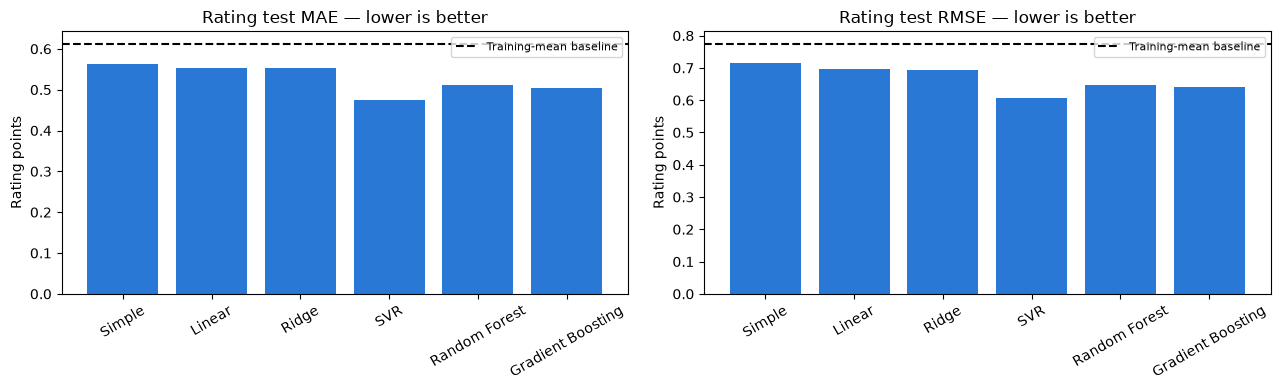

In [4]:
display(rating_test.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    ax.bar(rating_test.index, rating_test[metric], color=BLUE)
    reference_score = next(iter(rating_reports.values()))["baseline_test_metrics"][metric]
    ax.axhline(reference_score, color="black", linestyle="--", label="Training-mean baseline")
    ax.set(title=f"Rating test {metric} — lower is better", ylabel="Rating points")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=8)
finish(fig, "rating_error_comparison")

### Training versus test R²
A large gap suggests the model fits earlier training movies more closely than later movies. Changes over time can also contribute; this graph alone does not identify the cause.

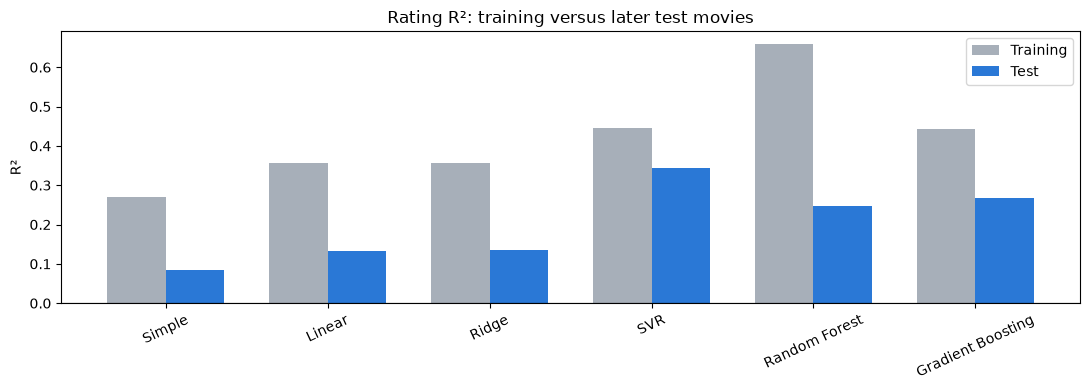

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
positions = np.arange(len(rating_test))
ax.bar(positions - 0.18, rating_train["R2"], width=0.36, color=GRAY, label="Training")
ax.bar(positions + 0.18, rating_test["R2"], width=0.36, color=BLUE, label="Test")
ax.set_xticks(positions, rating_test.index, rotation=25)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Rating R²: training versus later test movies", ylabel="R²")
ax.legend()
finish(fig, "rating_train_test_r2")

### Actual versus predicted ratings — every model
Points on the dashed diagonal are perfect predictions. A narrow band of predictions with widely varying actual ratings indicates that a model tends to predict near the middle.

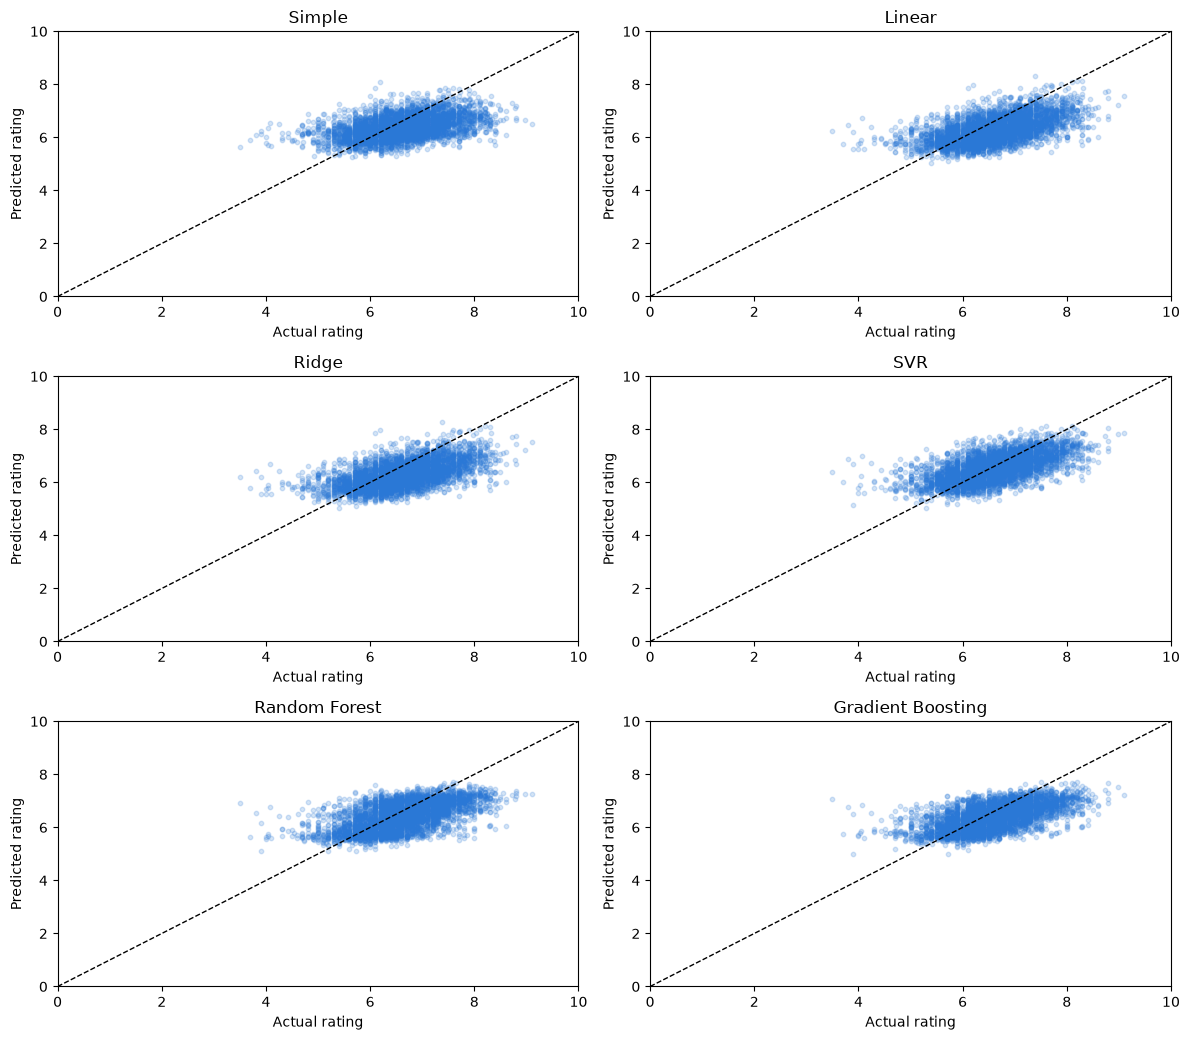

In [6]:
all_predictions = pd.concat([predictions(report) for report in rating_reports.values()], ignore_index=True)
prediction_limits = (min(0, all_predictions["predicted"].min() - 0.2), max(10, all_predictions["predicted"].max() + 0.2))
fig, axes = panel_grid(len(rating_reports))
for ax, (key, report) in zip(axes, rating_reports.items()):
    frame = predictions(report)
    ax.scatter(frame["actual"], frame["predicted"], alpha=0.2, s=10, color=BLUE)
    ax.plot([0, 10], [0, 10], "k--", linewidth=1)
    ax.set(title=LABELS[key], xlabel="Actual rating", ylabel="Predicted rating", xlim=(0, 10), ylim=prediction_limits)
finish(fig, "rating_actual_vs_predicted")

### Residuals — every model
Residual = actual rating minus prediction. Positive values mean underprediction; negative values mean overprediction. Patterns or widening spread suggest errors vary across the rating range.

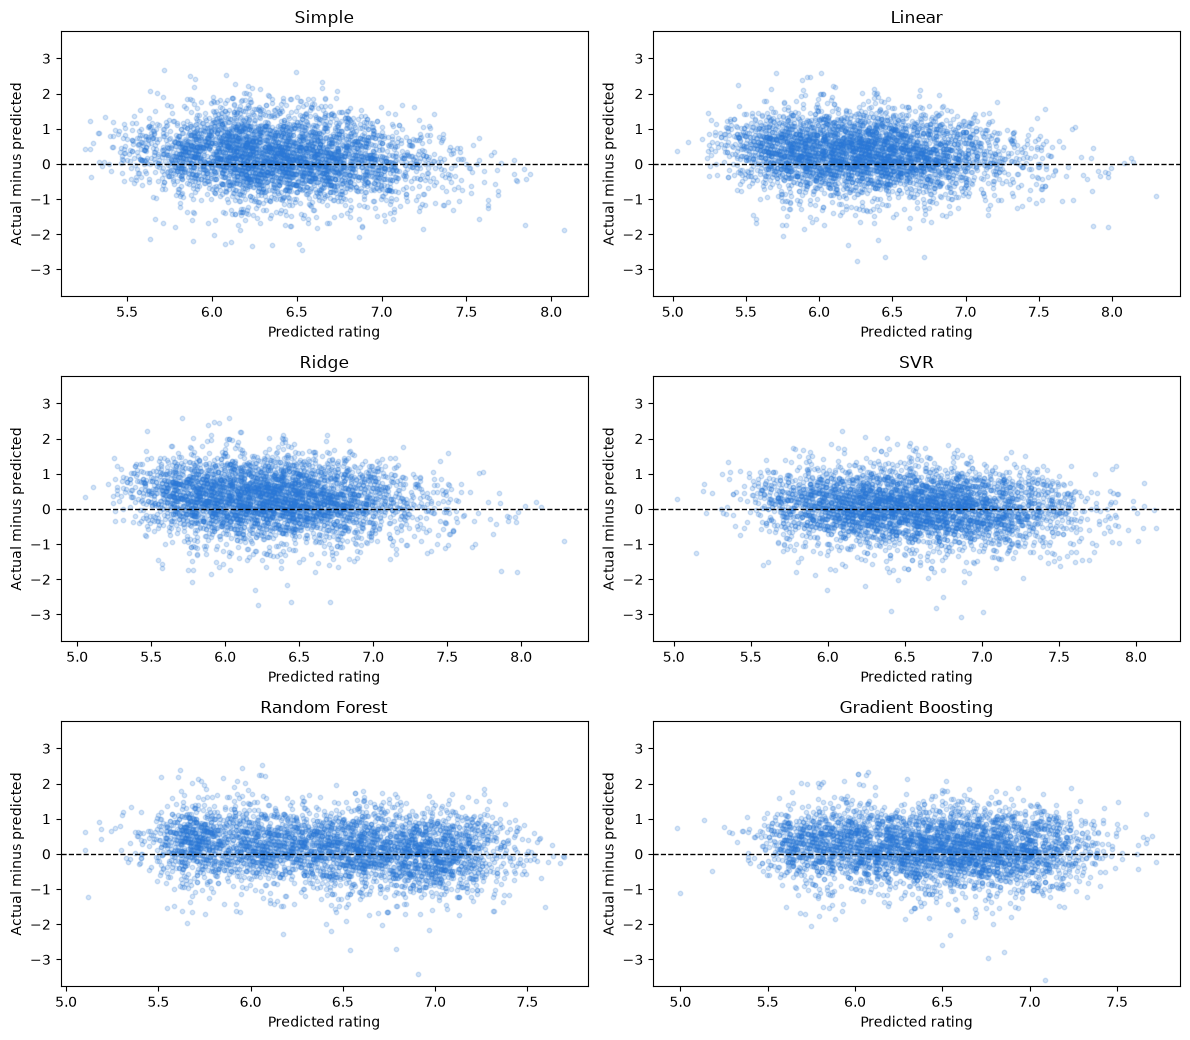

In [7]:
residual_limit = max(abs(predictions(report)["residual"]).max() for report in rating_reports.values()) * 1.05
fig, axes = panel_grid(len(rating_reports))
for ax, (key, report) in zip(axes, rating_reports.items()):
    frame = predictions(report)
    ax.scatter(frame["predicted"], frame["residual"], alpha=0.2, s=10, color=BLUE)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set(title=LABELS[key], xlabel="Predicted rating", ylabel="Actual minus predicted", ylim=(-residual_limit, residual_limit))
finish(fig, "rating_residuals")

## 3. Success models: precision, recall, and F1
**Precision:** how many predicted hits were actual hits. **Recall:** how many actual hits were found. **Hit F1:** their equal-weight harmonic mean. The 70% requirement is selected on validation data; it does not guarantee 70% later test precision.

,Accuracy,Balanced accuracy,Hit precision,Hit recall,Hit F1,ROC AUC
Simple,0.6857,0.5682,0.6389,0.1937,0.2973,0.6832
Logistic,0.6987,0.5957,0.6480,0.2674,0.3785,0.6968
Random Forest,0.6893,0.5911,0.6027,0.2779,0.3804,0.6851
Gradient Boosting,0.6763,0.5842,0.5542,0.2905,0.3812,0.6702


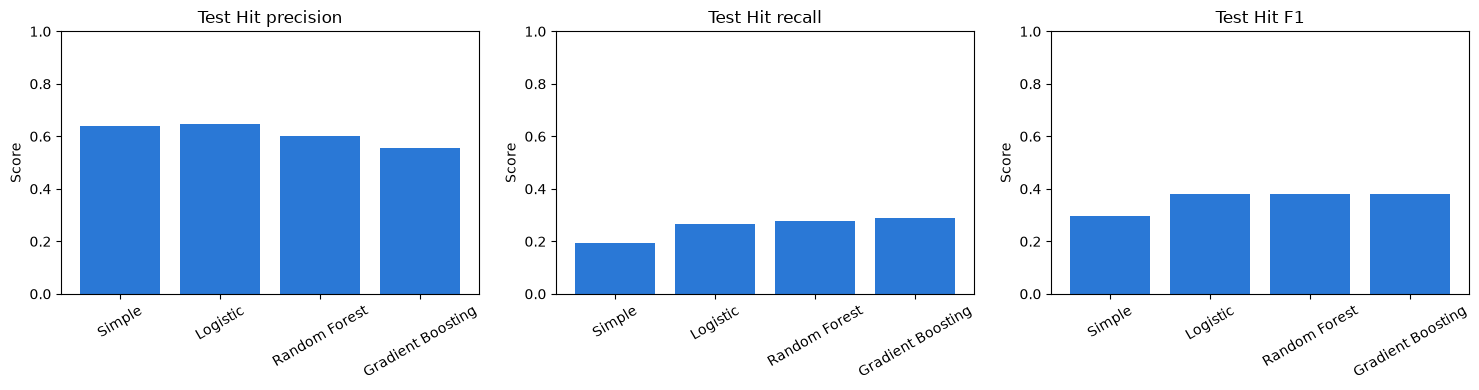

In [8]:
display(success_test.round(4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["Hit precision", "Hit recall", "Hit F1"]):
    ax.bar(success_test.index, success_test[metric], color=BLUE)
    ax.set(title=f"Test {metric}", ylim=(0, 1), ylabel="Score")
    ax.tick_params(axis="x", rotation=30)
finish(fig, "success_precision_recall_f1")

### Confusion matrices — every classifier
Rows are actual outcomes; columns are predictions. The top-right cell is a bust predicted as a hit. The bottom-left cell is a missed hit. Titles show the threshold used for this model version.

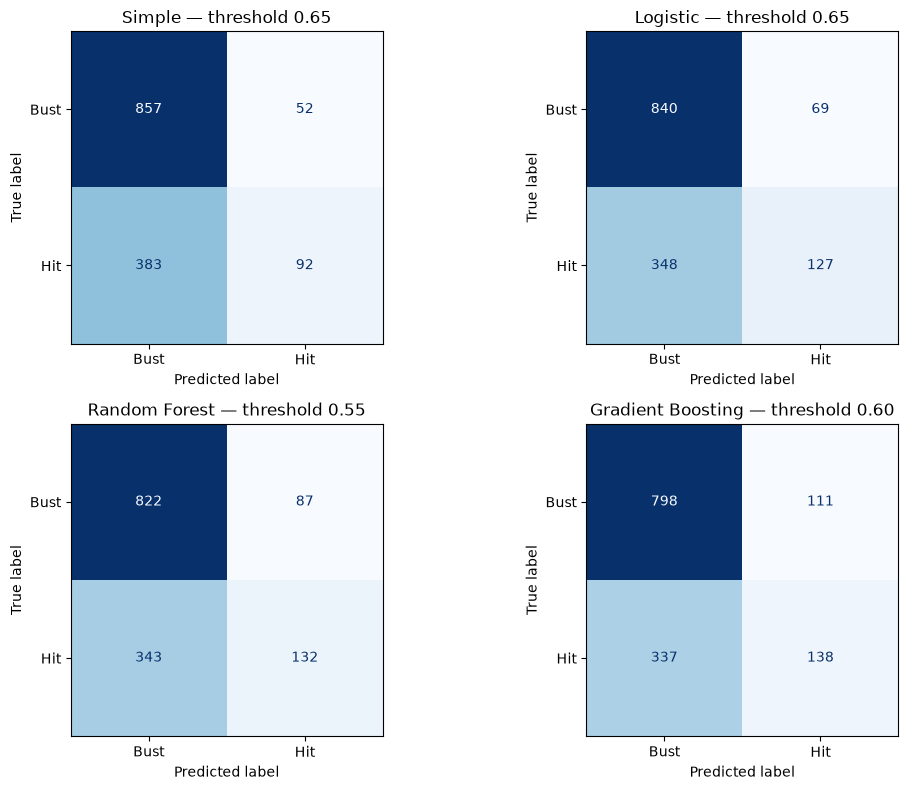

In [9]:
fig, axes = panel_grid(len(success_reports), width=11, height=4)
for ax, (key, report) in zip(axes, success_reports.items()):
    frame = predictions(report)
    ConfusionMatrixDisplay.from_predictions(frame["actual"], frame["predicted"], labels=[0, 1], display_labels=["Bust", "Hit"], colorbar=False, cmap="Blues", ax=ax)
    threshold = report["versions"][MODEL_VARIANT]["threshold"]
    ax.set_title(f"{LABELS[key]} — threshold {threshold:.2f}")
finish(fig, "success_confusion_matrices")

### ROC and precision–recall curves
These show ranking behavior across thresholds. AUC evaluates ranking, while the confusion matrices and F1 use the chosen threshold. The precision–recall reference is test hit prevalence. Do not pick a new threshold from these test curves; threshold selection belongs in training validation.

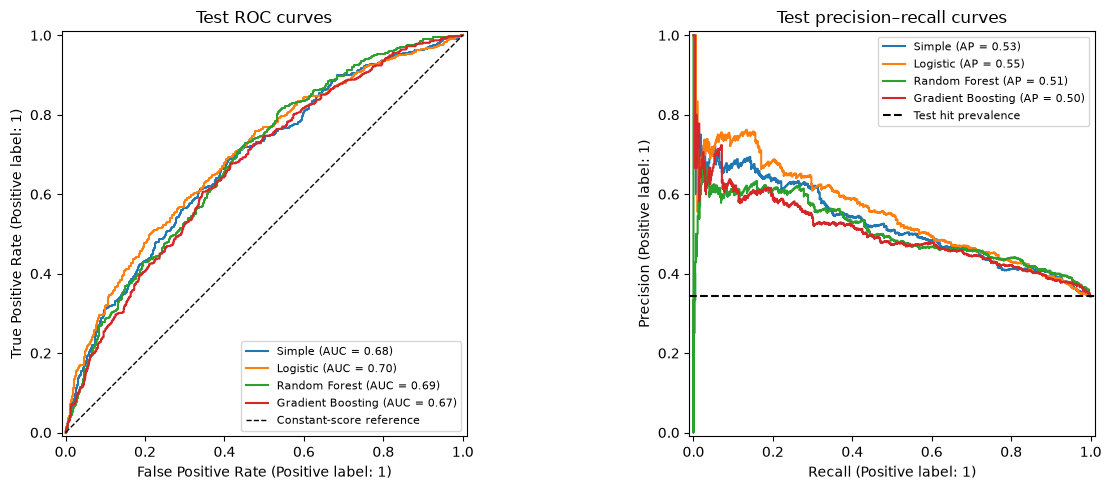

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for key, report in success_reports.items():
    frame = predictions(report)
    RocCurveDisplay.from_predictions(frame["actual"], frame["hit_probability"], name=LABELS[key], ax=axes[0])
    PrecisionRecallDisplay.from_predictions(frame["actual"], frame["hit_probability"], name=LABELS[key], ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Constant-score reference")
axes[1].axhline(success_actual.mean(), color="black", linestyle="--", label="Test hit prevalence")
axes[0].set_title("Test ROC curves")
axes[1].set_title("Test precision–recall curves")
for ax in axes: ax.legend(fontsize=8)
finish(fig, "success_roc_precision_recall")

### Training versus test ROC AUC
A large difference can indicate that ranking patterns learned from the training movies do not carry over well to later movies. ROC AUC is independent of the final classification threshold.

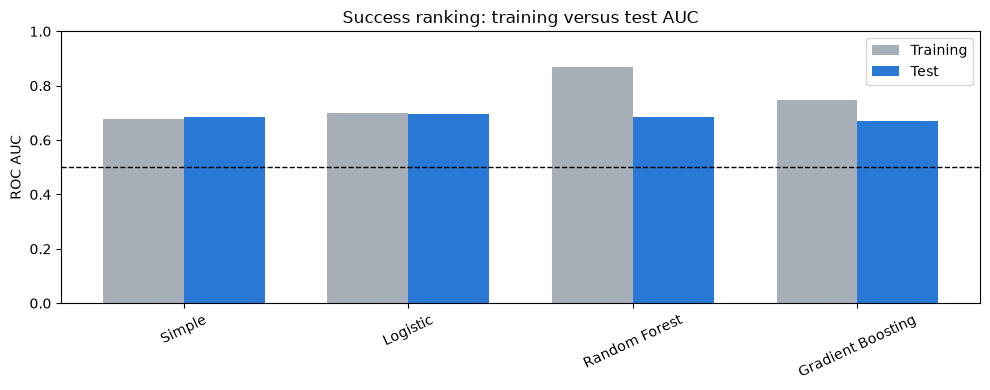

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
positions = np.arange(len(success_test))
ax.bar(positions - 0.18, success_train["ROC AUC"], width=0.36, color=GRAY, label="Training")
ax.bar(positions + 0.18, success_test["ROC AUC"], width=0.36, color=BLUE, label="Test")
ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
ax.set_xticks(positions, success_test.index, rotation=25)
ax.set(title="Success ranking: training versus test AUC", ylabel="ROC AUC", ylim=(0, 1))
ax.legend()
finish(fig, "success_train_test_auc")

## 4. Validation goals versus later outcomes
Validation values below are **reused selection estimates**, not untouched evaluations. The precision guard applies to validation averages; compare them with later test precision to understand why a selected requirement may not generalize.

,Validation precision,Test precision,Validation hit F1,Test hit F1,Precision requirement,Current version meets validation goal
Model,,,,,,
Simple,0.7069,0.6389,0.1524,0.2973,0.7,True
Logistic,0.7084,0.6480,0.1879,0.3785,0.7,True
Random Forest,0.7962,0.6027,0.1654,0.3804,0.7,True
Gradient Boosting,0.7153,0.5542,0.2214,0.3812,0.7,True


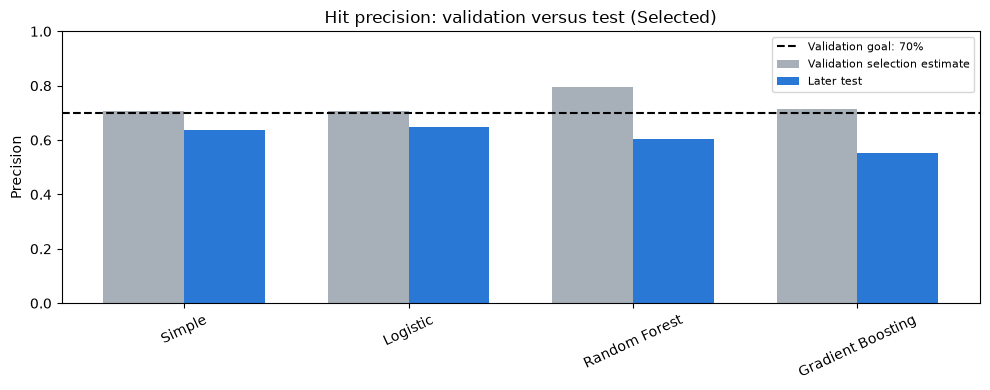

In [12]:
validation_rows = []
for key, report in success_reports.items():
    validation = report["versions"][MODEL_VARIANT]["validation"]
    validation_rows.append({
        "Model": LABELS[key], "Validation precision": validation.get("Hit precision", np.nan),
        "Test precision": report["versions"][MODEL_VARIANT]["test_metrics"]["Hit precision"],
        "Validation hit F1": validation.get("Hit F1", np.nan),
        "Test hit F1": report["versions"][MODEL_VARIANT]["test_metrics"]["Hit F1"],
        "Precision requirement": report["precision_goal"],
        "Current version meets validation goal": validation.get("Hit precision", np.nan) >= report["precision_goal"] if report["precision_goal"] is not None else None,
    })
validation_comparison = pd.DataFrame(validation_rows).set_index("Model")
display(validation_comparison.round(4))
fig, ax = plt.subplots(figsize=(10, 4))
positions = np.arange(len(validation_comparison))
ax.bar(positions - 0.18, validation_comparison["Validation precision"], width=0.36, color=GRAY, label="Validation selection estimate")
ax.bar(positions + 0.18, validation_comparison["Test precision"], width=0.36, color=BLUE, label="Later test")
goals = validation_comparison["Precision requirement"].dropna().unique()
if len(goals) == 1:
    ax.axhline(goals[0], color="black", linestyle="--", label=f"Validation goal: {goals[0]:.0%}")
ax.set_xticks(positions, validation_comparison.index, rotation=25)
ax.set(title=f"Hit precision: validation versus test ({MODEL_VARIANT})", ylabel="Precision", ylim=(0, 1))
ax.legend(fontsize=8)
finish(fig, "validation_vs_test_precision")

## 5. Which configuration produced these plots?
If you edit a model's top controls, save and Run All in that model before refreshing this notebook. Reports are checked against code and CSV fingerprints. Initial, settings-only, and selected versions are stored separately; the plots do not automatically choose a winner from test results.

In [13]:
configuration_rows = []
for task, reports in [("Rating", rating_reports), ("Success", success_reports)]:
    for key, report in reports.items():
        version = report["versions"][MODEL_VARIANT]
        configuration_rows.append({
            "Task": task, "Model": LABELS[key], "Variant": MODEL_VARIANT,
            "Predictors": len(version["features"]), "Threshold": version["threshold"],
            "Selection metric": report["selection_metric"],
            "Notebook": report["notebook"], "Report created (UTC)": report["created_utc"],
        })
display(pd.DataFrame(configuration_rows))
print("No model fitting or CSV writing occurred in this visualization notebook.")

,Task,Model,Variant,Predictors,Threshold,Selection metric,Notebook,Report created (UTC)
0,Rating,Simple,Selected,10,NaN,MAE,Modeling_scripts/rating_models/simple_model.ipynb,2026-11-04T04:24:20.905415+00:00
1,Rating,Linear,Selected,36,NaN,MAE,Modeling_scripts/rating_models/linear_model.ipynb,2026-11-04T04:23:26.691929+00:00
2,Rating,Ridge,Selected,36,NaN,MAE,Modeling_scripts/rating_models/ridge_model.ipynb,2026-11-04T04:24:18.602487+00:00
3,Rating,SVR,Selected,40,NaN,MAE,Modeling_scripts/rating_models/support_vector....,2026-11-04T04:26:39.089586+00:00
4,Rating,Random Forest,Selected,40,NaN,MAE,Modeling_scripts/rating_models/random_forest.i...,2026-11-04T04:24:15.373807+00:00
5,Rating,Gradient Boosting,Selected,40,NaN,MAE,Modeling_scripts/rating_models/gradient_boosti...,2026-11-04T04:23:23.660040+00:00
6,Success,Simple,Selected,10,0.65,Hit_F1,Modeling_scripts/success_models/simple_model.i...,2026-11-04T04:27:23.690277+00:00
7,Success,Logistic,Selected,36,0.65,Hit_F1,Modeling_scripts/success_models/logistic_regre...,2026-11-04T04:27:05.569645+00:00
8,Success,Random Forest,Selected,40,0.55,Hit_F1,Modeling_scripts/success_models/random_forest....,2026-11-04T04:27:20.452217+00:00
9,Success,Gradient Boosting,Selected,27,0.60,Hit_F1,Modeling_scripts/success_models/gradient_boost...,2026-11-04T04:27:00.251086+00:00


No model fitting or CSV writing occurred in this visualization notebook.


## Interpretation limits
Compare models only on matching tasks/test rows. The expanded rating cohort differs from older financially restricted rating experiments. Historical ratings and outcomes are retrospective snapshots and do not verify release-time availability. The validation and test periods have been inspected repeatedly, so these graphs describe exploratory results rather than independent confirmation or causal effects.